In [1]:
import pandas as pd
df_field = pd.read_csv("/Users/aditiiyer/Documents/Thesis/Combined_Data_24_25.csv")

In [2]:
df_field.head()

,Date,latitude,longitude,soil_moisture,soil_color,soil_texture,BD_inc_roots
0,2024-08-01,33.36280,78.01393,76.20,5Y4/1,sandy clay,0.320
1,2024-08-01,33.36272,78.01393,51.00,"2,5Y5/6;2,5Y3/3",sandy clay loam,0.335
2,2024-08-01,33.36282,78.01429,63.67,10YR5/6,sandy clay loam,0.363
3,2024-08-01,33.36291,78.01434,53.93,10YR5/3,clay,0.917
4,2024-08-01,33.36292,78.01453,55.03,10YR3/2,clay loam,0.591


In [3]:
df1=df_field.copy()

In [4]:
import numpy as np
import pandas as pd

usda_vertices = {
    "Sand": [(100,0,0),(90,10,0),(85,15,0),(100,0,0)],
    "Loamy Sand": [(90,10,0),(85,15,0),(70,30,0),(75,10,15),(90,10,0)],
    "Sandy Loam": [(70,30,0),(52,48,0),(52,28,20),(45,27,28),(50,0,50),(75,10,15),(70,30,0)],
    "Loam": [(52,28,20),(28,44,28),(22,28,50),(40,20,40),(43,34,23),(45,27,28),(52,28,20)],
    "Silt Loam": [(20,80,0),(0,100,0),(0,88,12),(8,42,50),(28,22,50),(28,44,28),(52,28,20),(43,34,23),(40,20,40),(22,28,50),(20,80,0)],
    "Silt": [(0,100,0),(0,88,12),(0,100,0)],
    "Sandy Clay Loam": [(45,27,28),(43,34,23),(65,35,0),(52,48,0),(52,28,20),(45,27,28)],
    "Clay Loam": [(28,44,28),(22,28,50),(40,20,40),(47,13,40),(55,25,20),(43,34,23),(28,44,28)],
    "Silty Clay Loam": [(28,22,50),(22,28,50),(0,50,50),(0,60,40),(8,42,50),(28,22,50)],
    "Sandy Clay": [(65,35,0),(55,45,0),(45,35,20),(55,25,20),(65,35,0)],
    "Silty Clay": [(0,60,40),(0,88,12),(8,42,50),(0,60,40)],
    "Clay": [(55,45,0),(45,35,20),(40,20,40),(47,13,40),(55,25,20),(55,45,0)]
}

def ternary_centroid(coords):
    arr = np.array(coords, dtype=float)
    c = arr.mean(axis=0)
    s = c.sum()
    if s != 0:
        c = c / s * 100
    return tuple(c)

centroids = {k: ternary_centroid(v) for k, v in usda_vertices.items()}

centroid_df = pd.DataFrame.from_dict(
    centroids,
    orient="index",
    columns=["sand_centroid","silt_centroid","clay_centroid"]
)

# soil_texture column must match centroid keys exactly; normalize if needed
df_field["soil_texture"] = df_field["soil_texture"].str.strip().str.title()

df = df_field.merge(
    centroid_df,
    left_on="soil_texture",
    right_index=True,
    how="left"
)

df1 = df.drop(columns=["soil_texture"])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/ternary/plotting.py:148: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(xs, ys, vmin=vmin, vmax=vmax, **kwargs)


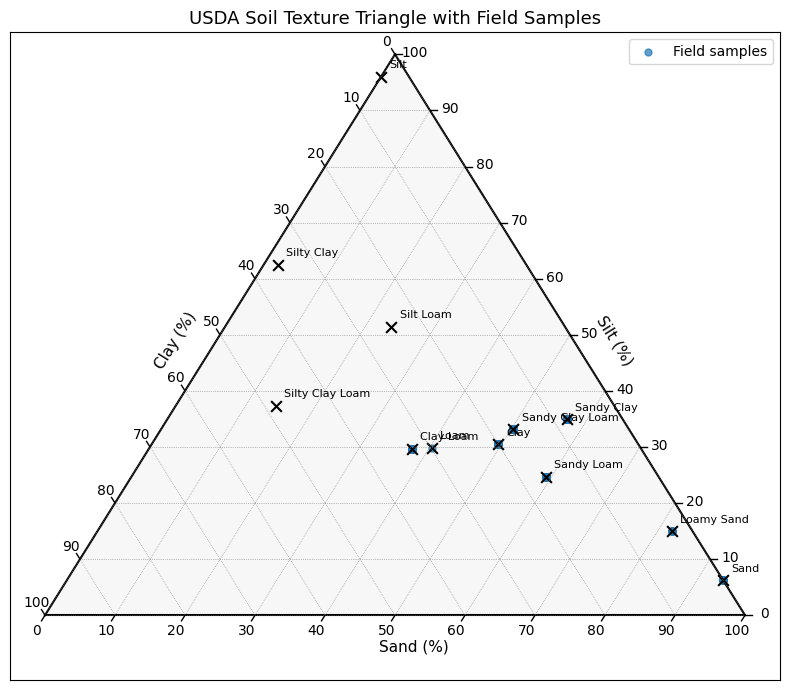

In [5]:
import ternary
import matplotlib.pyplot as plt

points = df[["sand_centroid", "silt_centroid", "clay_centroid"]].dropna().values.tolist()

fig, tax = ternary.figure(scale=100)
fig.set_size_inches(8, 7)

tax.boundary(linewidth=1.5)
tax.gridlines(multiple=10, color="gray", linewidth=0.5)

tax.left_axis_label("Clay (%)", fontsize=11)
tax.right_axis_label("Silt (%)", fontsize=11)
tax.bottom_axis_label("Sand (%)", fontsize=11, offset=-0.10)

tax.scatter(
    points,
    marker="o",
    color="tab:blue",
    s=25,
    alpha=0.7,
    label="Field samples"
)

for name, (sand, silt, clay) in centroids.items():
    tax.scatter(
        [(sand, silt, clay)],
        marker="x",
        color="black",
        s=60
    )

    tax.annotate(
        name,
        (sand, silt, clay),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8
    )

tax.ticks(axis="lbr", multiple=10, linewidth=1)
tax.clear_matplotlib_ticks()
tax.legend(loc="upper right")
tax.set_title("USDA Soil Texture Triangle with Field Samples", fontsize=13)

plt.tight_layout()
plt.show()

In [6]:
len(points)

119